## Libraries

In [112]:
import tensorflow as tf
from keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Rescaling, Resizing, RandomFlip, RandomRotation
import os
import random
import numpy as np
from glob import glob
import pandas as pd
import matplotlib.pyplot as plt

## Paths and Constants

In [113]:
path_train = r"../Data/dataset_yawn_eye/train"
path_test = r"../Data/dataset_yawn_eye/test/"
# labels_name = os.listdir(path_train)


## Preprocessing
Create and store tensorflow records for training and validation data

In [114]:
def label_2_bytes(val):
    if isinstance(val, type(tf.constant(0))): 
        val = val.numpy() 

    return tf.train.Feature(bytes_list = tf.train.BytesList(value = [val]))


def encode(img, label_encoded):
    feature = {
        'image' : tf.train.Feature(bytes_list = tf.train.BytesList(value = [img])),
        'label' : label_2_bytes(tf.io.serialize_tensor(label_encoded))
    }
    
    example = tf.train.Example(features = tf.train.Features(feature = feature))

    return example.SerializeToString()



def write_tf_record(record_path, files):
    labels=['Closed','Open']

    with tf.io.TFRecordWriter(record_path, options = tf.io.TFRecordOptions(compression_type = "GZIP")) as writer:
                random.shuffle(files)

                for file in files:
                    label_encoding = np.array([0,0], dtype='float64')
                    img = open(file, 'rb').read()
                    current_label = file.split('/')[-2]
                    current_label = labels.index(current_label)
                    label_encoding[current_label] = 1.0 # one-hot-encoding
                    tf_example = encode(img, label_encoding)

                    writer.write(tf_example)


def get_combined_files(path):
    files_list = glob(path + '/Closed/*')
    files_list1 = glob(path + '/Open/*')
    com_list = files_list + files_list1

    return com_list

def create_record_training(path):
    combined_files = get_combined_files(path)

    write_tf_record("../Data/tfrecords/training", combined_files)

    
def create_record_validation(path):
    combined_files = get_combined_files(path)

    write_tf_record("../Data/tfrecords/test", combined_files[ : len(combined_files) // 2])
    write_tf_record("../Data/tfrecords/validation", combined_files[len(combined_files) // 2 : ])
       

### Call methods to create tensorflow records

In [115]:
create_record_training(path_train)
create_record_validation(path_test)

### Create tensorflow dataset from records

In [116]:
def map_img_2_label(tf_example):
    feature = {
        "image" : tf.io.FixedLenFeature([], tf.string),
        "label" : tf.io.FixedLenFeature([], tf.string)
    }

    features = tf.io.parse_single_example(tf_example, feature)

    img = tf.io.decode_jpeg(features["image"], channels = 3)
    img = tf.image.resize(img, (256, 256))
    label = tf.io.parse_tensor(features["label"], out_type = tf.float64)
    label = tf.reshape(label, shape = (2, ))

    return img, label


def data_config(data: tf.data.TFRecordDataset, batch_size):
    data = data.map(map_img_2_label, tf.data.experimental.AUTOTUNE)
    data = data.shuffle(512)
    data = data.batch(batch_size, True)
    data = data.prefetch(tf.data.experimental.AUTOTUNE)

    return data


def read_dataset_from_tf_record(file, batch_size):
    read_data = tf.data.TFRecordDataset(file, "GZIP")
    dataset = data_config(read_data, batch_size)

    return dataset


def get_data_from_records(batch_size = 32):
    train_data = read_dataset_from_tf_record("../Data/tfrecords/training", batch_size)
    test_data = read_dataset_from_tf_record("../Data/tfrecords/test", batch_size)
    validation_data = read_dataset_from_tf_record("../Data/tfrecords/validation", batch_size)

    return train_data, test_data, validation_data

In [117]:
train_data, test_data, validation_data = get_data_from_records()

In [121]:
callback = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath = "../Data/models/cnn_model_epochs.h5", 
        monitor = "val_accuracy", 
        save_best_only = True, 
        mode = "max",
        verbose = 0
    )
]


## CNN Model

In [122]:
cnn_model = tf.keras.Sequential([
    Resizing(256, 256),
    Rescaling(1./255),
    RandomFlip(mode="horizontal"),
    RandomRotation(factor=0.4, fill_mode="reflect", interpolation="bilinear"),
    Conv2D(32, 3, activation="relu"),
    MaxPooling2D(),
    Conv2D(32, 3, activation="relu"),
    MaxPooling2D(),
    Conv2D(32, 3, activation="relu"),
    MaxPooling2D(),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(2, activation="softmax")
])

cnn_model.compile(optimizer="adam", loss=tf.losses.CategoricalCrossentropy(), metrics=["accuracy"])


In [123]:
trained_model = cnn_model.fit(
    x = train_data, 
    epochs = 10, 
    callbacks = callback,
    validation_data = validation_data
)


Epoch 1/10


38/38 [==============================] - 35s 889ms/step - loss: 0.4571 - accuracy: 0.7755 - val_loss: 0.2465 - val_accuracy: 0.8854
Epoch 2/10
38/38 [==============================] - 33s 856ms/step - loss: 0.2414 - accuracy: 0.9021 - val_loss: 0.0704 - val_accuracy: 0.9688
Epoch 3/10
38/38 [==============================] - 34s 887ms/step - loss: 0.2350 - accuracy: 0.9038 - val_loss: 0.1607 - val_accuracy: 0.9375
Epoch 4/10
38/38 [==============================] - 33s 848ms/step - loss: 0.1966 - accuracy: 0.9219 - val_loss: 0.3622 - val_accuracy: 0.8125
Epoch 5/10
38/38 [==============================] - 29s 757ms/step - loss: 0.2144 - accuracy: 0.9202 - val_loss: 0.0782 - val_accuracy: 0.9688
Epoch 6/10
38/38 [==============================] - 29s 738ms/step - loss: 0.1993 - accuracy: 0.9252 - val_loss: 0.1612 - val_accuracy: 0.9479
Epoch 7/10
38/38 [==============================] - 28s 736ms/step - loss: 0.1835 - accuracy: 0.9268 - val_loss: 0.2424 - val_accuracy: 0.8646
Epoch 8/10

In [124]:
cnn_model.summary()

Model: "sequential_7"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 resizing_7 (Resizing)       (32, 256, 256, 3)         0         
                                                                 
 rescaling_7 (Rescaling)     (32, 256, 256, 3)         0         
                                                                 
 random_flip_7 (RandomFlip)  (32, 256, 256, 3)         0         
                                                                 
 random_rotation_7 (RandomR  (32, 256, 256, 3)         0         
 otation)                                                        
                                                                 
 conv2d_21 (Conv2D)          (32, 254, 254, 32)        896       
                                                                 
 max_pooling2d_21 (MaxPooli  (32, 127, 127, 32)        0         
 ng2D)                                                

#### Evaluation of model

<Axes: >

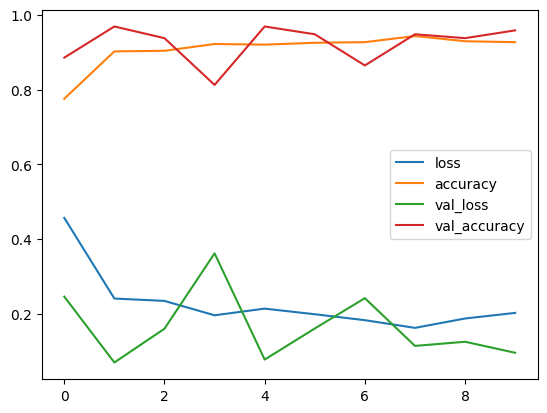

In [125]:
pd.DataFrame(trained_model.history).plot()

In [126]:
cnn_model.evaluate(validation_data)

3/3 [==============================] - 1s 243ms/step - loss: 0.0790 - accuracy: 0.9688


[0.07901684194803238, 0.96875]

In [127]:
cnn_model.evaluate(test_data)

3/3 [==============================] - 1s 216ms/step - loss: 0.3338 - accuracy: 0.8958


[0.3337614834308624, 0.8958333134651184]

In [128]:
cnn_model.save("../Data/models/eye_classifier.h5")

/Users/simon/envs/datascience/lib/python3.11/site-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(
